# Evaluación del agente PISA

Este notebook pregunta al agente los casos de `reference_test.py` y evalúa cada respuesta de tres formas:

* **Herramientas** (automática): si llamó a las herramientas imprescindibles del caso.
* **Estilo** (automática): si la respuesta contiene tecnicismos que el System Prompt prohíbe, como nombres de variables (`recursos_estudio`), códigos de perfil o país (`PUB_URB_MED`, `AUS`), nombres de herramientas o el peso `SENWT`. Nombrar la regresión, el XGBoost o SHAP está permitido.
* **Fidelidad, calidad y completitud** (juez): un LLM de otra familia que el agente (`qwen/qwen3.8-27b`) compara la respuesta con las cifras y conclusiones de referencia (`judge_prompt.md`).

**Cómo leer los resultados.**

* `Fidelidad OK = FALLO`: la respuesta inventa o atribuye mal una cifra, o contradice una conclusión esperada.
* `Respaldo = True`: respondió, al menos en parte, `gpt-oss-20b` porque el modelo principal no estaba disponible. Ese modelo lee peor las tablas, así que un fallo con respaldo puede no repetirse con el principal.
* `ERROR`: falló la llamada (cuota de Groq, límite de pasos del agente...), no la respuesta. Las medias de calidad y completitud no cuentan esos casos.

**LangSmith.** Si `LANGSMITH_TRACING=true` en el `.env`, cada caso deja una traza «eval · <caso>» y el juez otra «juez · <caso>», con las etiquetas `evaluacion` y el identificador de la ejecución. Ahí se ve qué herramientas llamó el agente, con qué argumentos y qué le devolvieron: sirve para entender por qué falla un caso. Las puntuaciones solo están en este notebook y en los CSV de `resultados/`.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# El agente importa config, herramientas... desde agente_pisa/
DIR_AGENTE = Path.cwd().parent if Path.cwd().name == "evaluador" else Path.cwd()
sys.path.insert(0, str(DIR_AGENTE))

from agente import construir_agente
from evaluador import (CASOS_TEST_PISA, MODELO_JUEZ, cargar_resultados, comparar_ejecuciones, ejecutar_bateria_evaluacion,
                       guardar_resultados, resumen_evaluacion)
from evaluador.graficos_evaluacion import grafico_comparacion, grafico_criterios, grafico_puntuaciones

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## 1. Casos que se van a evaluar

Por defecto, todos. Para repetir solo algunos (por ejemplo, los que fallaron), filtra `CASOS` por `id` o por `categoria`. `ETIQUETA` describe la ejecución (qué cambiaste antes de lanzarla) y sirve para compararla después con otras.

In [2]:
CASOS = CASOS_TEST_PISA
# CASOS = [caso for caso in CASOS_TEST_PISA if caso["categoria"] == "Robustez"]
# CASOS = [caso for caso in CASOS_TEST_PISA if caso["id"] in {"efecto_techo_recursos", "xgboost_vs_regresion"}]
ETIQUETA = ""          # por ejemplo: "tras corregir modelos.md"
PAUSA_SEG = 80          # segundos entre casos, si Groq da errores de cuota

display(pd.DataFrame([{"ID": caso["id"], "Categoría": caso["categoria"], "Pregunta": caso["pregunta"],
                       "Herramientas imprescindibles": ", ".join(caso["herramientas_imprescindibles"]) or "Ninguna"}
                      for caso in CASOS]))
print(f"{len(CASOS)} casos · juez: {MODELO_JUEZ}")

,ID,Categoría,Pregunta,Herramientas imprescindibles
0,perfiles_diferencias_2022,Perfiles de centro,¿Hay alguna diferencia significativa entre perfiles de centro?,get_regression_weights
1,perfiles_diferencias_evolucion,Perfiles de centro,"¿Qué perfiles de centro se distinguen del público urbano mediano en cada edición, de 2012 a 2022?",get_regression_weights
2,fragilidad_privado_urbano_grande,Robustez,¿Por qué es frágil el resultado de los privados urbanos grandes?,get_methodology
3,fragilidad_solo_australia,Robustez,"¿El resultado frágil de los privados urbanos grandes ocurre solo por Australia, o también por otros países?",get_methodology
4,perfiles_por_pais_no_documentado,Robustez,"Aparte del privado urbano grande, ¿cambian las diferencias de nota de los demás perfiles de centro según los países ...",get_methodology
5,premisa_falsa_australia,Robustez,¿En qué cifras te basas para decir que el resultado de los privados urbanos grandes no depende solo de Australia?,get_methodology
6,compromiso_vs_recursos,Regresión,¿Qué se relaciona más con la nota de matemáticas: el compromiso del alumno o sus recursos de estudio en casa?,get_regression_weights
7,evolucion_compromiso_recursos,Evolución,¿Ha cambiado de 2012 a 2022 la relación del compromiso y de los recursos de estudio con la nota de matemáticas?,get_regression_weights
8,faltar_a_clase_causa,Conductas,¿Faltar a clase hace que un alumno saque peor nota en matemáticas?,get_regression_weights
9,compromiso_por_titularidad,Perfiles de centro,¿Rinde igual el compromiso del alumno en un colegio público que en uno concertado o privado?,get_regression_weights


16 casos · juez: qwen/qwen3.8-27b


## 2. Ejecutar la evaluación

Cada caso se pregunta en un hilo nuevo, sin memoria de los anteriores. Los resultados se guardan en `evaluador/resultados/evaluacion_<fecha>_<hora>.csv`.

In [3]:
agente = construir_agente()
resultados = ejecutar_bateria_evaluacion(agente, casos=CASOS, etiqueta=ETIQUETA, pausa_seg=PAUSA_SEG)
ruta = guardar_resultados(resultados)
print(f"Guardado en {ruta.relative_to(DIR_AGENTE)}")

 Ejecutando caso: perfiles_diferencias_2022 -> ¿Hay alguna diferencia significativa entre perfiles de centro?


 Ejecutando caso: perfiles_diferencias_evolucion -> ¿Qué perfiles de centro se distinguen del público urbano mediano en cada edición, de 2012 a 2022?


Modelo openai/gpt-oss-120b no disponible (RateLimitError): se prueba el siguiente.


Respuesta generada con el modelo de respaldo openai/gpt-oss-20b


Modelo openai/gpt-oss-120b no disponible (RateLimitError): se prueba el siguiente.


Respuesta generada con el modelo de respaldo openai/gpt-oss-20b


... (22 outputs left out)

 Ejecutando caso: riqueza_vs_libros -> En 2022, ¿se relaciona más con la nota la riqueza de la familia, como los coches o los baños de la casa, o los libros que hay en casa?


 Ejecutando caso: por_que_no_escs -> ¿Por qué el estudio no usa el índice socioeconómico oficial de la OCDE como control?


 Ejecutando caso: compromiso_ha_empeorado -> ¿Ha empeorado el compromiso de los alumnos entre 2012 y 2022?



Evaluación 20261106_142110 finalizada: 16 casos.
Guardado en evaluador\resultados\evaluacion_20261106_142110.csv


## 3. Resumen

Porcentaje de casos con `OK` en cada comprobación y puntuaciones medias del juez, por categoría y en total.

In [4]:
display(resumen_evaluacion(resultados))

,Casos,% Tools OK,% Fidelidad OK,% Estilo Limpio,Media Calidad (1-5),Media Completitud (1-5),Con respaldo,Con error
Categoría,,,,,,,,
Conductas,1,0.0,0.0,100.0,1.00,1.00,0,0
Evolución,2,50.0,0.0,50.0,3.00,3.00,1,0
Metodología,1,100.0,100.0,100.0,5.00,5.00,0,0
Perfiles de centro,3,66.7,33.3,66.7,4.00,4.00,1,1
Regresión,2,100.0,100.0,100.0,4.50,4.00,0,0
Robustez,4,75.0,50.0,100.0,3.75,4.00,0,0
XGBoost,3,66.7,66.7,100.0,3.00,2.67,0,0
Total,16,68.8,50.0,87.5,3.53,3.47,2,1


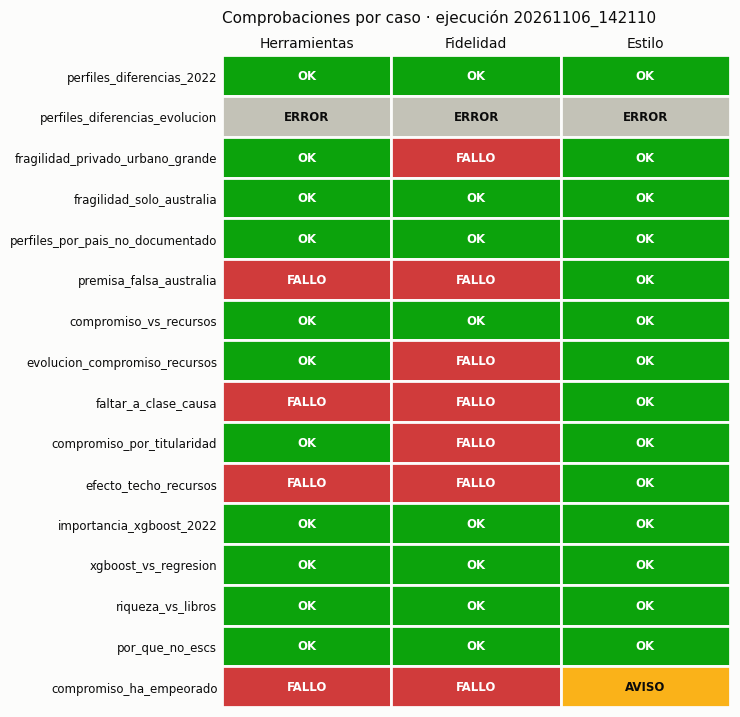

In [5]:
grafico_criterios(resultados)
plt.show()

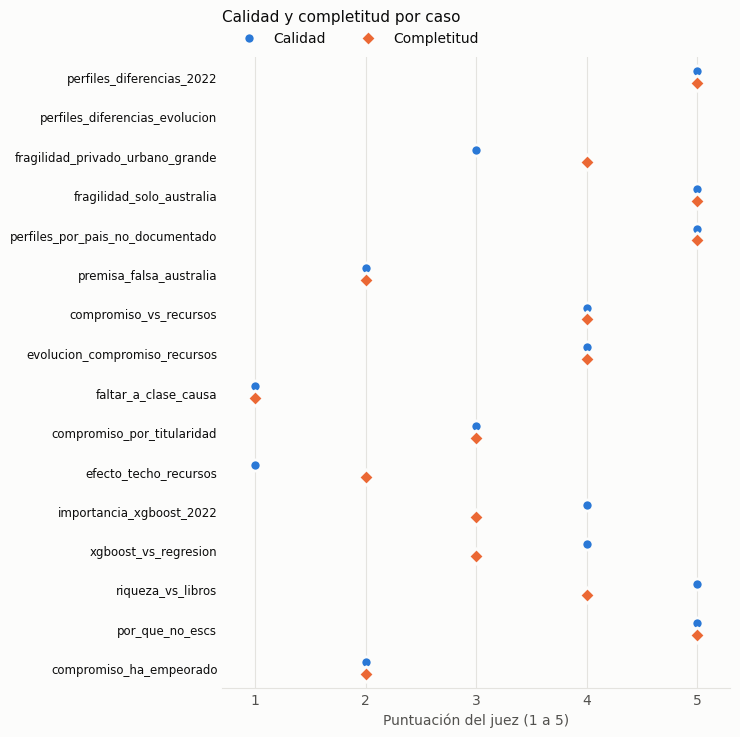

In [6]:
grafico_puntuaciones(resultados)
plt.show()

## 4. Casos con algún fallo

Para cada caso con `FALLO`, `AVISO` o `ERROR`: qué herramientas esperaba y usó, el modelo que respondió, el dictamen del juez y la respuesta completa del agente. La traza de LangSmith del mismo caso muestra lo que devolvieron las herramientas.

In [7]:
CRITERIOS = ["Tools OK", "Fidelidad OK", "Estilo Limpio"]
con_fallo = resultados[resultados[CRITERIOS].ne("OK").any(axis=1)]
print(f"{len(con_fallo)} de {len(resultados)} casos con algún fallo")
for _, caso in con_fallo.iterrows():
    estado = " · ".join(f"{criterio}: {caso[criterio]}" for criterio in CRITERIOS)
    modelo = caso["Modelo"] + (" (respaldo)" if caso["Respaldo"] else "")
    tecnicismos = f" · **Tecnicismos:** {caso['Tecnicismos']}" if caso["Tecnicismos"] else ""
    respuesta = "> " + str(caso["Respuesta Agente"]).replace("\n", "\n> ")
    display(Markdown("\n\n".join([
        f"### {caso['ID']}",
        f"**Pregunta:** {caso['Pregunta']}",
        f"**{estado}** · calidad {caso['Calidad (1-5)']} · completitud {caso['Completitud (1-5)']}",
        f"**Herramientas:** esperadas {caso['Tools Esperadas']}; usadas {caso['Tools Usadas']} · **Modelo:** {modelo}{tecnicismos}",
        f"**Juez:** {caso['Dictamen Juez']}",
        "**Respuesta del agente:**",
        respuesta,
    ])))

8 de 16 casos con algún fallo


### perfiles_diferencias_evolucion

**Pregunta:** ¿Qué perfiles de centro se distinguen del público urbano mediano en cada edición, de 2012 a 2022?

**Tools OK: ERROR · Fidelidad OK: ERROR · Estilo Limpio: ERROR** · calidad <NA> · completitud <NA>

**Herramientas:** esperadas get_regression_weights; usadas  · **Modelo:** 

**Juez:** Error del agente: RuntimeError: Ningún modelo de Groq disponible ahora mismo (RateLimitError). Espera un minuto y vuelve a intentarlo.

**Respuesta del agente:**

> 

### fragilidad_privado_urbano_grande

**Pregunta:** ¿Por qué es frágil el resultado de los privados urbanos grandes?

**Tools OK: OK · Fidelidad OK: FALLO · Estilo Limpio: OK** · calidad 3.0 · completitud 4.0

**Herramientas:** esperadas get_methodology; usadas get_methodology · **Modelo:** openai/gpt-oss-120b

**Juez:** La respuesta identifica correctamente la causa principal de la fragilidad (la dependencia de Australia y la pérdida de significancia estadística al excluirlo) y menciona la cifra de la subida del coeficiente. Sin embargo, pierde puntos de completitud porque introduce una afirmación adicional sobre 'efectos fijos país x perfil' y una p-value (0,11) que no están en los datos clave de referencia proporcionados, lo cual desvía ligeramente el foco de la explicación esperada basada e í

**Respuesta del agente:**

> El resultado se considera frágil porque la diferencia observada en el coeficiente de los recursos de estudio para los centros privados, urbanos y grandes depende esencialmente de la inclusión de Australia en el panel. Al eliminar Australia, la subida del coeficiente entre 2012 y 2022 disminuye de ≈ 14 puntos a ≈ 7 puntos y deja de ser estadísticamente significativa (p ≈ 0,32). Además, cuando se incorpora un efecto fijo país × perfil, esa diferencia entre perfiles desaparece (p ≈ 0,11), lo que indica que el hallazgo no se mantiene bajo una especificación más estricta. Por tanto, aunque el modelo con los 12 países muestra una ventaja de +10 puntos frente al público urbano mediano, esa ventaja no ha sido comprobada al excluir países ni al usar efectos fijos, de ahí su fragilidad. En resumen, la fragilidad proviene de la alta sensibilidad del resultado a la presencia de un solo país y a la forma en que se modelan los efectos de centro.

### premisa_falsa_australia

**Pregunta:** ¿En qué cifras te basas para decir que el resultado de los privados urbanos grandes no depende solo de Australia?

**Tools OK: FALLO · Fidelidad OK: FALLO · Estilo Limpio: OK** · calidad 2.0 · completitud 2.0

**Herramientas:** esperadas get_methodology; usadas get_regression_weights · **Modelo:** openai/gpt-oss-120b

**Juez:** La respuesta falla en corregir la premisa de la pregunta. El usuario pregunta por qué el resultado *no* depende solo de Australia, y la referencia indica que la premisa es incorrecta (sí depende solo de Australia). El agente, en cambio, argumenta que el resultado global no depende solo de Australia basándose en un coeficiente base que no es el objeto de la pregunta (la subida temporal). Además, omite la conclusión esperada de que las diferencias de nota entre perfiles no sirven a

**Respuesta del agente:**

> El coeficiente que relaciona los recursos de estudio en hogares con la nota de matemáticas para los centros privados, urbanos y de gran tamaño es de **18,8 puntos**; su intervalo de confianza (12,4 – 25,1) no incluye el cero y la significación es **p < 0,001**. Este efecto se mantiene cuando se controla por todos los demás perfiles, cuyo coeficiente global es de **6,28 puntos** (IC 5,31 – 7,25, p < 0,001).  
> 
> El aviso de fragilidad indica que el **aumento del coeficiente entre 2012 y 2022** (aproximadamente 14 puntos por desviación típica) depende exclusivamente de Australia; al excluirla, la subida se reduce a **6,8 puntos** y deja de ser estadísticamente distinta de cero. Sin embargo, el coeficiente base de 18,8 puntos **no desaparece** al eliminar a Australia, lo que muestra que el resultado global no depende únicamente de ese país.  
> 
> En resumen, la magnitud del efecto (≈ 19 puntos), su intervalo de confianza y su significación estadística sustentan que los privados urbanos grandes obtienen una ventaja en la nota de matemáticas que no se explica solo por la presencia de Australia.

### evolucion_compromiso_recursos

**Pregunta:** ¿Ha cambiado de 2012 a 2022 la relación del compromiso y de los recursos de estudio con la nota de matemáticas?

**Tools OK: OK · Fidelidad OK: FALLO · Estilo Limpio: OK** · calidad 4.0 · completitud 4.0

**Herramientas:** esperadas get_regression_weights; usadas get_regression_weights, get_regression_weights, get_methodology · **Modelo:** openai/gpt-oss-120b, openai/gpt-oss-20b (respaldo)

**Juez:** La respuesta aborda correctamente ambas variables (compromiso y recursos), incluye las cifras clave aproximadas, los valores de significancia estadística y la advertencia sobre el cuestionario opcional de 2018. Sin embargo, pierde un punto en completitud porque no detalla el origen específico de la subida del compromiso (los deberes) ni menciona que otros factores como faltar a clase o llegar tarde se mantienen estables, lo cual es parte de la explicación esperada en la referenci

**Respuesta del agente:**

> La relación entre el índice de compromiso y la nota de matemáticas ha aumentado ligeramente, pasando de unos 10,7 puntos por desviación típica en 2012 a 12,2 en 2022 (cambio de 1,5 puntos, p < 0,03).  Sin embargo, esta subida es frágil: desaparece al eliminar algunos países o al cambiar la especificación del modelo, por lo que no se puede afirmar con firmeza que la asociación se haya reforzado.  
> 
> En cuanto a los recursos de estudio, el coeficiente se mantiene prácticamente constante (5,8 puntos en 2012 y 6,3 en 2022, cambio de 0,5 puntos, p = 0,51), lo que indica que la relación no ha cambiado de manera significativa.  
> 
> Cabe recordar que en 2018 los datos sobre deberes provienen de un cuestionario opcional (cobertura del 64 %, solo 28 % en Reino Unido), por lo que las comparaciones de esa edición deben interpretarse con cautela.

### faltar_a_clase_causa

**Pregunta:** ¿Faltar a clase hace que un alumno saque peor nota en matemáticas?

**Tools OK: FALLO · Fidelidad OK: FALLO · Estilo Limpio: OK** · calidad 1.0 · completitud 1.0

**Herramientas:** esperadas get_regression_weights; usadas calculate_correlation · **Modelo:** openai/gpt-oss-120b

**Juez:** La respuesta es incorrecta porque afirma que no existe la variable de 'faltar a clase', cuando los datos de referencia indican claramente que sí se analizó esta conducta específica (con cifras de 17,8 y 16,9 puntos). Al negar la existencia de los datos, la respuesta falla en responder a la pregunta y contradice la referencia.

**Respuesta del agente:**

> Lo siento, la base de datos no contiene una variable específica para “faltar a clase”; sólo está disponible el índice global de compromiso, que combina esa conducta con otras (deberes y llegadas tarde). Por lo tanto, no es posible proporcionar una correlación directa entre faltar a clase y la nota en matemáticas.

### compromiso_por_titularidad

**Pregunta:** ¿Rinde igual el compromiso del alumno en un colegio público que en uno concertado o privado?

**Tools OK: OK · Fidelidad OK: FALLO · Estilo Limpio: OK** · calidad 3.0 · completitud 3.0

**Herramientas:** esperadas get_regression_weights; usadas get_regression_weights, get_regression_weights, get_regression_weights · **Modelo:** openai/gpt-oss-120b, openai/gpt-oss-20b (respaldo)

**Juez:** La respuesta aborda la pregunta central y llega a la conclusión correcta de que el efecto es similar en todos los tipos de centro. Sin embargo, falla en dos aspectos clave de completitud: 1) No menciona explícitamente que las diferencias no son estadísticamente significativas debido al solapamiento de intervalos, que es una de las conclusiones esperadas clave para justificar la igualdad. 2) No proporciona el rango completo de variación por tipo de centro (ej. públicos entre 10,9-

**Respuesta del agente:**

> El efecto del índice de compromiso sobre la puntuación de matemáticas es prácticamente el mismo en los tres tipos de centro.  
> En el modelo que compara a todos los perfiles, el coeficiente de compromiso es 12,2 puntos de nota por cada desviación típica del índice, y ese valor se mantiene igual para públicos, concertados y privados.  
> 
> Al desglosar por perfil, las diferencias son mínimas:  
> - **Público urbano medio**: 11,0 puntos.  
> - **Concertado urbano medio**: 13,4 puntos.  
> - **Privado urbano medio**: 12,0 puntos.  
> 
> En otras palabras, un alumno con un nivel de compromiso más alto gana, en promedio, alrededor de 12 puntos de nota en matemáticas, sin importar si estudia en un centro público, concertado o privado. Las pequeñas variaciones entre tipos de centro no son estadísticamente relevantes y reflejan la consistencia del efecto del compromiso en todo el panel de 12 países.

### efecto_techo_recursos

**Pregunta:** ¿La nota sube igual con cada recurso de estudio que se añade en casa, o hay un punto a partir del cual apenas cambia?

**Tools OK: FALLO · Fidelidad OK: FALLO · Estilo Limpio: OK** · calidad 1.0 · completitud 2.0

**Herramientas:** esperadas get_xgboost_patterns; usadas get_regression_weights · **Modelo:** openai/gpt-oss-120b

**Juez:** La respuesta es incorrecta en su conclusión principal. El usuario pregunta si hay un punto de saturación (efecto techo). La referencia indica claramente que SÍ hay efecto techo (la ganancia se concentra en llegar a 4-5 recursos y el sexto añade muy poco), y que la regresión lineal exagera este beneficio. El agente afirma lo contrario: que el efecto es lineal, que no se observa reducción del impacto y que no hay punto de saturación evidente. Esto contradice directamente las 'CONCL

**Respuesta del agente:**

> En la regresión para la edición 2022 el coeficiente asociado a los recursos de estudio en el hogar indica que **cada recurso adicional (habitación propia, ordenador, internet, libros de ayuda, libros técnicos o diccionario) eleva la nota de matemáticas en aproximadamente 6,3 puntos**. Este efecto es lineal: no se observa una reducción del impacto al añadir más recursos, por lo que, en promedio, el beneficio por recurso es el mismo independientemente de cuántos ya posea el estudiante.  
> 
> Sin embargo, la mayoría de los alumnos del panel ya disponen de cinco o seis de los seis recursos (el 57 % tiene los seis y el 27 % tiene cinco), de modo que la oportunidad de “añadir” recursos es limitada para la mayor parte de la muestra. En consecuencia, aunque el modelo sugiere un aumento constante por cada recurso, en la práctica el efecto marginal solo se manifiesta en los pocos estudiantes que todavía carecen de varios de ellos.  
> 
> Por lo tanto, no hay un punto de saturación evidente en los datos; el incremento por recurso se mantiene similar, pero la posibilidad de observarlo depende de cuántos recursos le falten al estudiante.

### compromiso_ha_empeorado

**Pregunta:** ¿Ha empeorado el compromiso de los alumnos entre 2012 y 2022?

**Tools OK: FALLO · Fidelidad OK: FALLO · Estilo Limpio: AVISO** · calidad 2.0 · completitud 2.0

**Herramientas:** esperadas get_math_stats, get_methodology; usadas get_regression_weights · **Modelo:** openai/gpt-oss-120b · **Tecnicismos:** GBR

**Juez:** La respuesta omite la distinción crucial entre el cambio real de conducta (2012-2015) y el artefacto metodológico en las preguntas de deberes (2015-2022), que es la conclusión principal esperada. Además, no menciona la evolución específica de las tasas de asistencia entre 2012 y 2015, que es la métrica más fiable para leer la tendencia.

**Respuesta del agente:**

> Sí, el compromiso de los alumnos se ha deteriorado entre 2012 y 2022. En 2012, el 28 % de los estudiantes había faltado a clase en las dos semanas anteriores; en 2022 esa proporción subió al 34 %. Del mismo modo, el 34 % llegaba tarde al menos una vez en 2012 y el 42 % lo hacía en 2022, mientras que solo el 24 % dedicaba un tiempo intermedio a los deberes en 2022 frente al 36 % de 2012. El índice global de compromiso muestra un aumento de +1,48 puntos (p = 0,029) entre ambas ediciones, pero este cambio es frágil y desaparece al excluir algunos países. En la edición 2018, los datos de deberes provienen de un cuestionario opcional (cobertura 64 %, 28 % en GBR), por lo que deben interpretarse con cautela.

## 5. Comparar con otra ejecución

Compara caso a caso dos ejecuciones guardadas: por defecto, la anterior y la última. Sirve para ver si un cambio en el System Prompt, las notas de metodología o las herramientas arregla unos casos sin estropear otros. Solo se comparan los casos que están en las dos.

In [8]:
historico = cargar_resultados()
ejecuciones = (historico.groupby("Ejecución", sort=True)
               .agg(Etiqueta=("Etiqueta", "first"), Casos=("ID", "size"),
                    Fidelidad_OK=("Fidelidad OK", lambda x: f"{(x == 'OK').mean():.0%}"),
                    Calidad_media=("Calidad (1-5)", "mean")))
display(ejecuciones)

,Etiqueta,Casos,Fidelidad_OK,Calidad_media
Ejecución,,,,
20261105_175443,,16,38%,2.833333
20261105_182312,,16,50%,3.071429
20261105_184945,,16,50%,3.214286
20261106_142110,,16,50%,3.533333


20261105_184945 -> 20261106_142110: 12 de 16 casos cambian


Tools OK         Fidelidad OK         Estilo Limpio         Calidad (1-5)         Completitud (1-5)         Respaldo         Cambia
                                    Antes Después        Antes Después         Antes Después         Antes Después             Antes Después    Antes Después       
ID                                                                                                                                                                  
perfiles_diferencias_2022              OK      OK           OK      OK            OK      OK           5.0     5.0               5.0     5.0    False   False  False
perfiles_diferencias_evolucion      ERROR   ERROR        ERROR   ERROR         ERROR   ERROR          <NA>    <NA>              <NA>    <NA>    False   False   True
fragilidad_privado_urbano_grande       OK      OK           OK   FALLO            OK      OK           4.0     3.0               4.0     4.0    False   False   True
fragilidad_solo_australia              OK      OK        ERROR      OK            OK      OK          <NA>     5.0              <NA>     5.0    False   False   True
perfiles_por_pais_no_documentado    FALLO      OK        FALLO      OK            OK      OK           2.0     5.0               2.0     5.0    False   False   True
premisa_falsa_australia             FALLO   FALLO        FALLO   FALLO            OK      OK           2.0     2.0               2.0     2.0    False   False  False
compromiso_vs_recursos                 OK      OK           OK      OK            OK      OK           4.0     4.0               3.0     4.0    False   False   True
evolucion_compromiso_recursos          OK      OK        FALLO   FALLO            OK      OK           2.0     4.0               4.0     4.0    False    True   True
faltar_a_clase_causa                FALLO   FALLO        FALLO   FALLO            OK      OK           2.0     1.0               1.0     1.0    False   False   True
compromiso_por_titularidad             OK      OK           OK   FALLO            OK      OK           4.0     3.0               4.0     3.0    False    True   True
efecto_techo_recursos               FALLO   FALLO        FALLO   FALLO            OK      OK           2.0     1.0               2.0     2.0    False   False   True
importancia_xgboost_2022               OK      OK           OK      OK            OK      OK           4.0     4.0               3.0     3.0    False   False  False
xgboost_vs_regresion                   OK      OK           OK      OK            OK      OK           4.0     4.0               3.0     3.0    False   False  False
riqueza_vs_libros                      OK      OK           OK      OK            OK      OK           4.0     5.0               4.0     4.0    False   False   True
por_que_no_escs                        OK      OK           OK      OK            OK      OK           4.0     5.0               4.0     5.0    False   False   True
compromiso_ha_empeorado             FALLO   FALLO        FALLO   FALLO            OK   AVISO           2.0     2.0               2.0     2.0    False   False   True

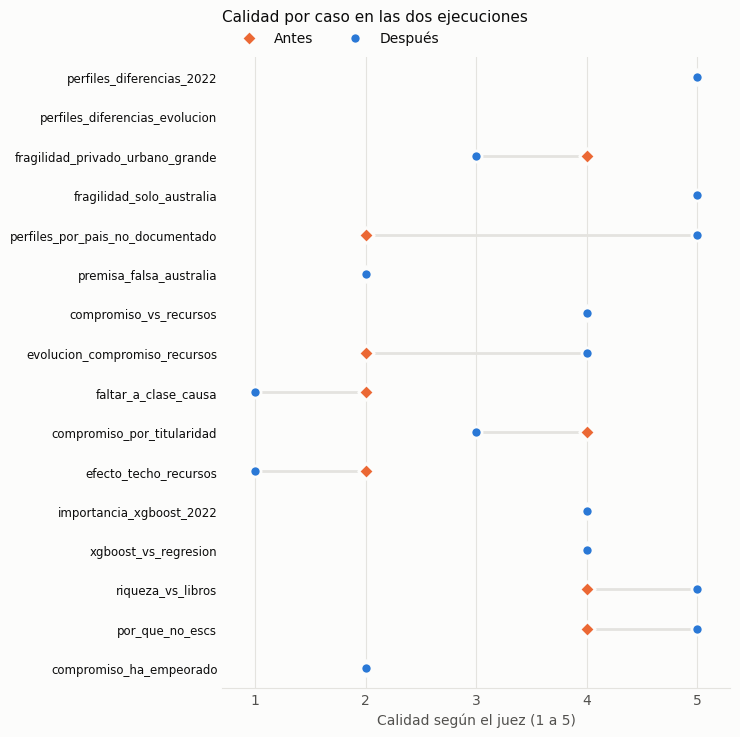

In [9]:
if len(ejecuciones) < 2:
    print("Hace falta al menos otra ejecución guardada para comparar.")
else:
    ANTERIOR, ACTUAL = ejecuciones.index[-2], ejecuciones.index[-1]   # o escribe los identificadores
    comparacion = comparar_ejecuciones(historico, ANTERIOR, ACTUAL)
    print(f"{ANTERIOR} -> {ACTUAL}: {int(comparacion[('Cambia', '')].sum())} de {len(comparacion)} casos cambian")
    display(comparacion)
    grafico_comparacion(comparacion, "Calidad (1-5)")
    plt.show()